# Notebook 2 — Signal Generation

## Core Methodology: Network Features → Audio Signals

Each network flow feature is:
1. **MinMax scaled** to [0, 1]
2. **Mapped to a frequency** fᵢ ∈ [200, 4000] Hz
3. **Rendered** as sin(2πfᵢt)
4. **Superposed** into a composite waveform

This transforms tabular intrusion detection into an **audio classification** problem.


In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Audio, display

from preprocessing import DataLoader, FeatureProcessor
from signal_generator import SignalGenerator, MIN_FREQ, MAX_FREQ

FIG_DIR = '../data/signals'
import os; os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs('../reports/figures', exist_ok=True)

SAMPLE_SIZE = 500
RANDOM_STATE = 42


## 1. Load and Prepare Features


In [2]:
loader = DataLoader(data_dir='../data/raw')
train_df, _ = loader.load_nsl_kdd(sample_size=SAMPLE_SIZE)

processor = FeatureProcessor()
X, y, feat_names = processor.prepare_features(train_df, fit=True)

# Select representative samples
benign_idx = np.where(y == 0)[0][:3]
attack_idx = np.where(y == 1)[0][:3]

print(f"Features: {len(feat_names)}")
print(f"Benign samples: {benign_idx}")
print(f"Attack samples: {attack_idx}")


Features: 38
Benign samples: [0 5 9]
Attack samples: [1 2 3]


## 2. Initialize Signal Generator


In [3]:
sig_gen = SignalGenerator(
    sample_rate=22050,
    duration=2.0,
    min_freq=MIN_FREQ,
    max_freq=MAX_FREQ,
)
sig_gen.fit(X)
print(f"Sample rate: {sig_gen.sample_rate} Hz")
print(f"Duration: {sig_gen.duration}s → {sig_gen.n_samples} samples")
print(f"Frequency range: [{sig_gen.min_freq}, {sig_gen.max_freq}] Hz")


Sample rate: 22050 Hz
Duration: 2.0s → 44100 samples
Frequency range: [200.0, 4000.0] Hz


## 3. Individual Feature Waves

Visualize how each feature contributes a unique frequency component.


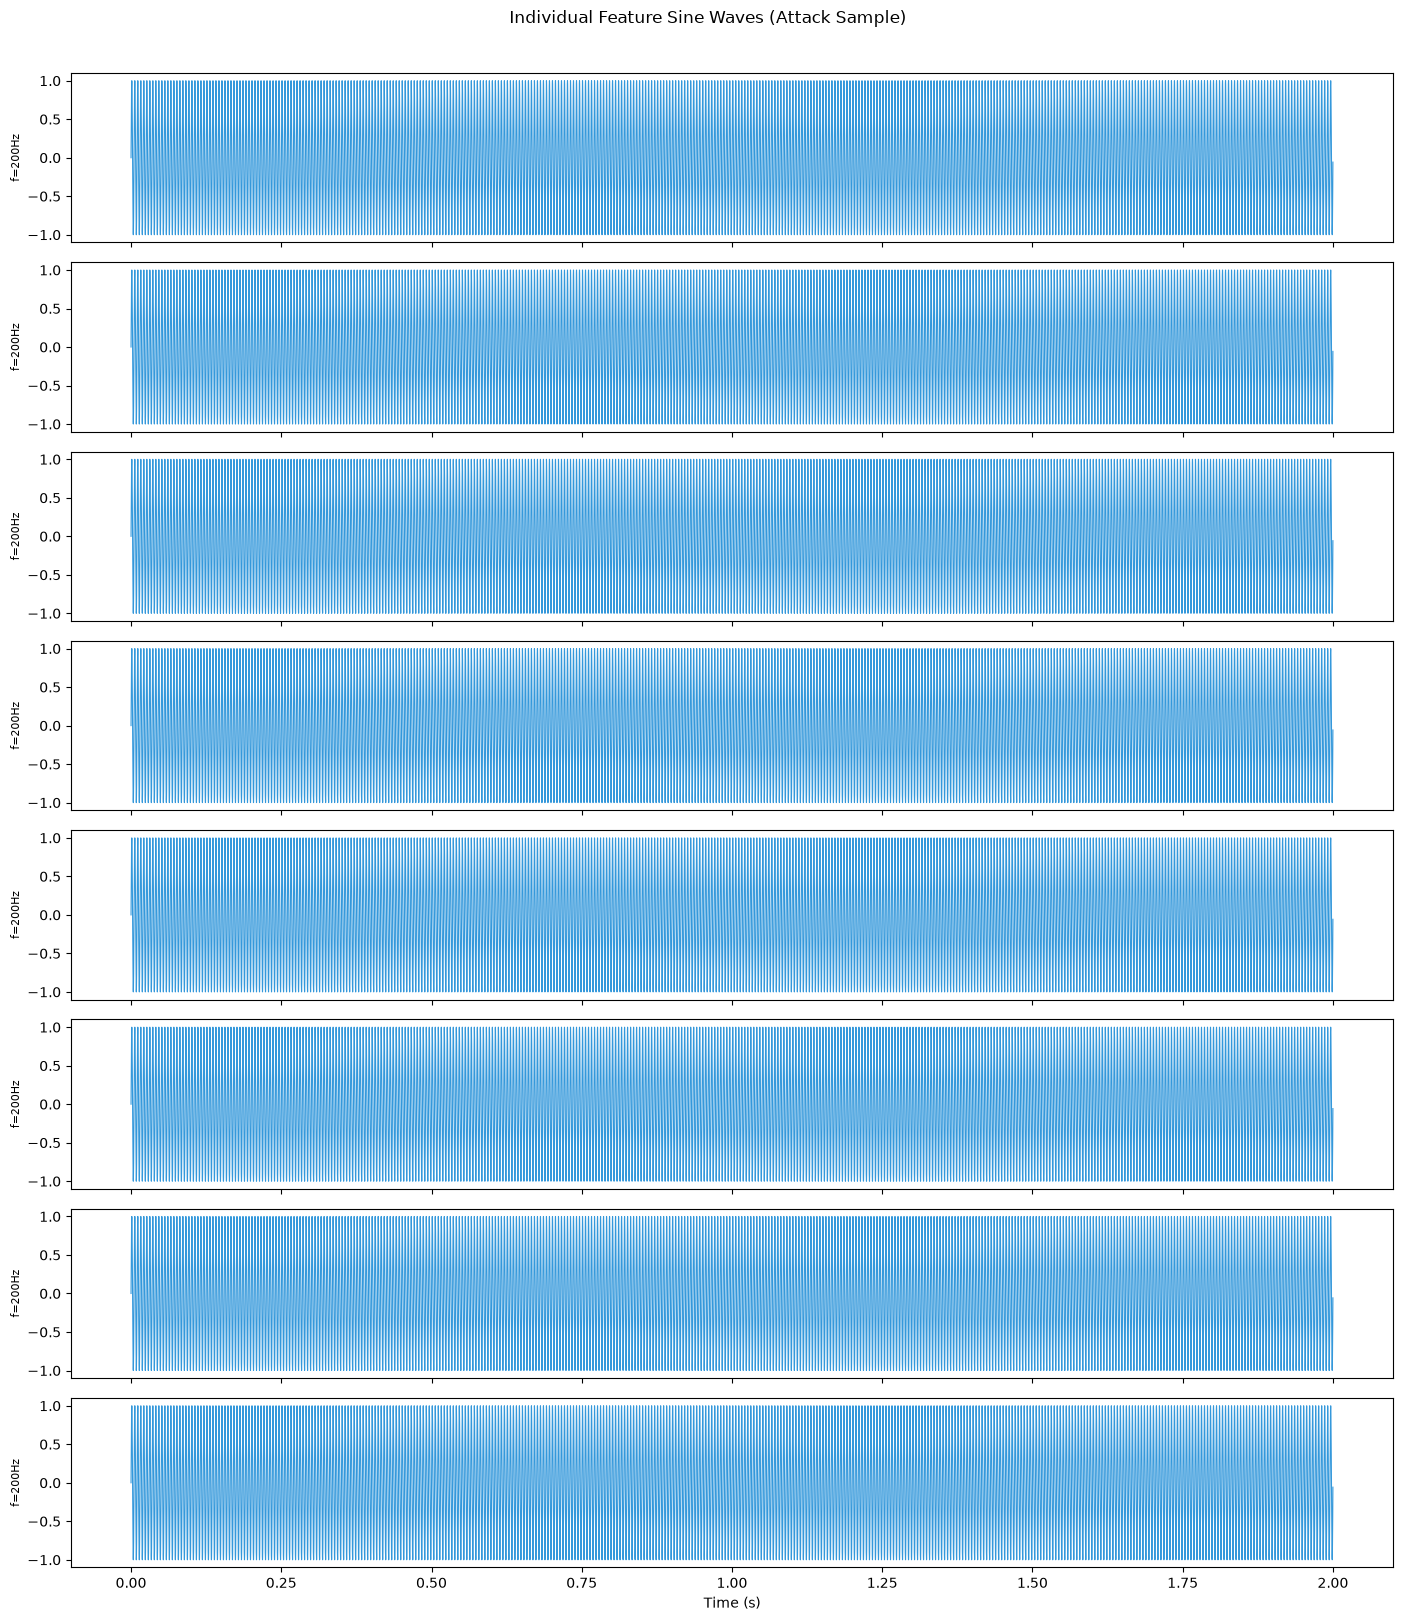

In [4]:
sample = X[attack_idx[0]]
freqs, waves = sig_gen.generate_component_waves(sample)

# Plot first 8 component waves
n_show = min(8, len(waves))
fig, axes = plt.subplots(n_show, 1, figsize=(14, 2 * n_show), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(sig_gen.time_axis, waves[i], color='#3498db', linewidth=0.8)
    ax.set_ylabel(f'f={freqs[i]:.0f}Hz', fontsize=8)
    ax.set_ylim(-1.1, 1.1)
axes[-1].set_xlabel('Time (s)')
fig.suptitle('Individual Feature Sine Waves (Attack Sample)', y=1.01)
plt.tight_layout()
plt.savefig('../reports/figures/08_component_waves.png', dpi=300, bbox_inches='tight')
plt.show()


## 4. Combined Superposition Signal


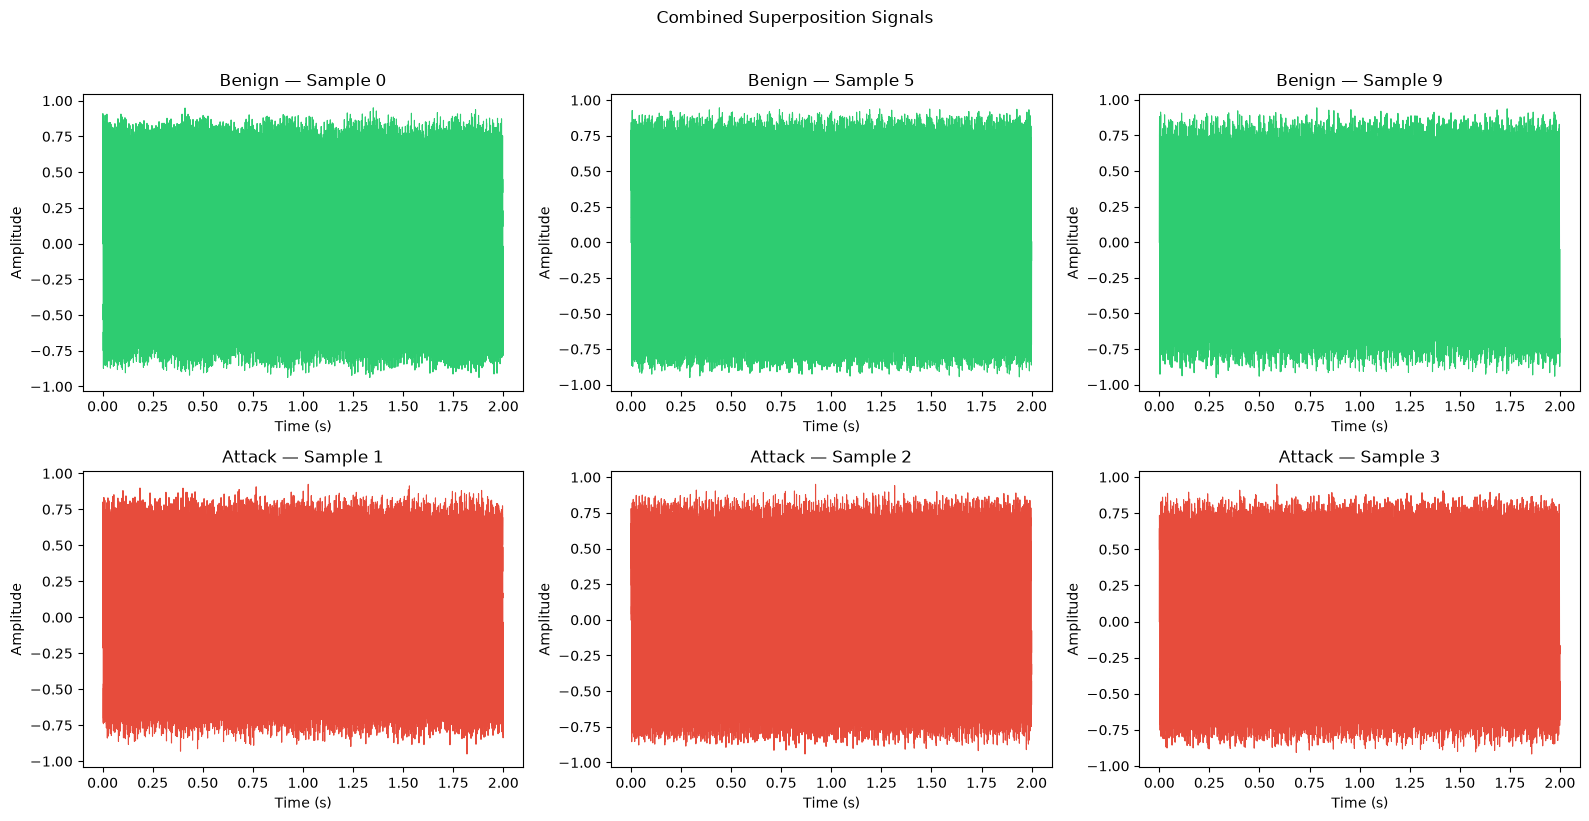

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

samples = [(benign_idx[i], 'Benign') for i in range(3)] + [(attack_idx[i], 'Attack') for i in range(3)]

for ax, (idx, label) in zip(axes.flatten(), samples):
    signal = sig_gen.generate_signal(X[idx])
    ax.plot(sig_gen.time_axis, signal, linewidth=0.8,
            color='#2ecc71' if label == 'Benign' else '#e74c3c')
    ax.set_title(f'{label} — Sample {idx}')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Amplitude')

plt.suptitle('Combined Superposition Signals', y=1.02)
plt.tight_layout()
plt.savefig('../reports/figures/09_combined_waveforms.png', dpi=300, bbox_inches='tight')
plt.show()


## 5. FFT Spectrum Analysis


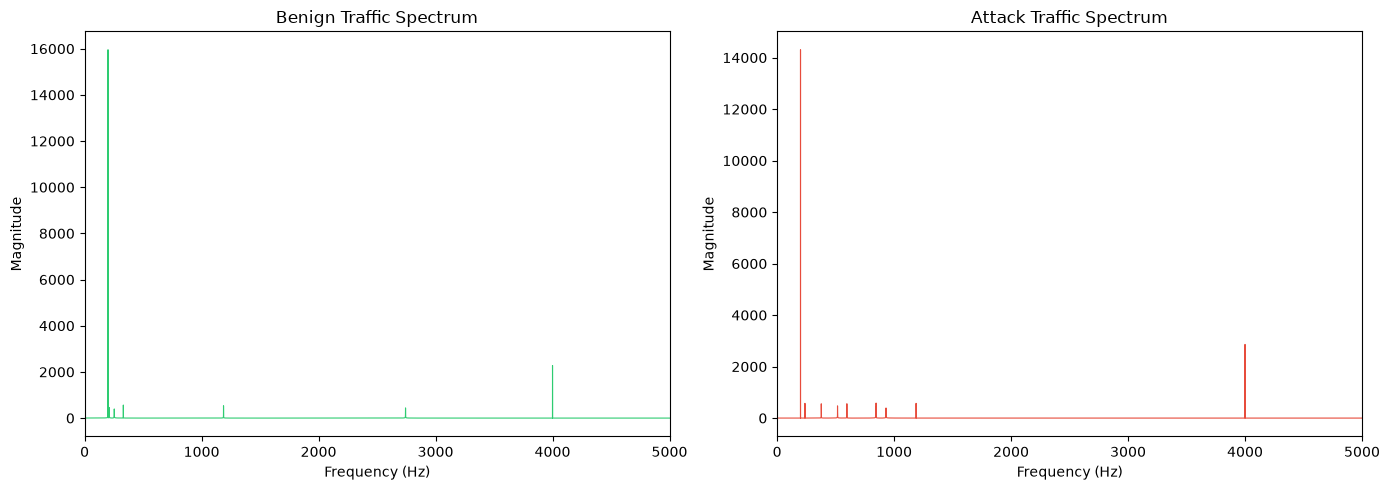

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

benign_signal = sig_gen.generate_signal(X[benign_idx[0]])
attack_signal = sig_gen.generate_signal(X[attack_idx[0]])

for ax, signal, title, color in [
    (axes[0], benign_signal, 'Benign Traffic Spectrum', '#2ecc71'),
    (axes[1], attack_signal, 'Attack Traffic Spectrum', '#e74c3c'),
]:
    freqs_fft, magnitude = sig_gen.compute_fft(signal)
    ax.plot(freqs_fft, magnitude, color=color, linewidth=0.8)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Magnitude')
    ax.set_title(title)
    ax.set_xlim(0, 5000)

plt.tight_layout()
plt.savefig('../reports/figures/10_fft_spectrum.png', dpi=300, bbox_inches='tight')
plt.show()


## 6. Frequency Distribution of Mapped Features


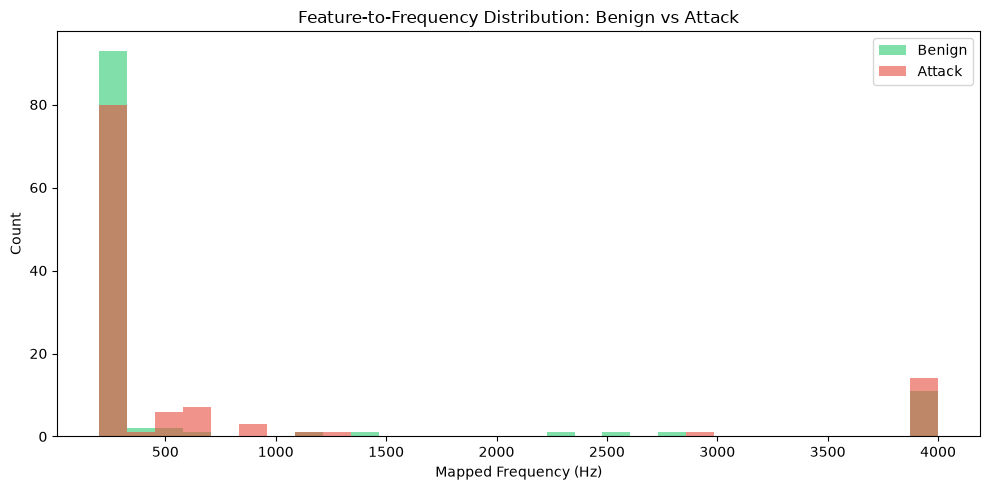

In [7]:
benign_freqs = sig_gen.features_to_frequencies(X[benign_idx])
attack_freqs = sig_gen.features_to_frequencies(X[attack_idx])

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(benign_freqs.flatten(), bins=30, alpha=0.6, label='Benign', color='#2ecc71')
ax.hist(attack_freqs.flatten(), bins=30, alpha=0.6, label='Attack', color='#e74c3c')
ax.set_xlabel('Mapped Frequency (Hz)')
ax.set_ylabel('Count')
ax.set_title('Feature-to-Frequency Distribution: Benign vs Attack')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/11_frequency_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


## 7. Save WAV Files and Playback


In [8]:
# Generate and save signals
all_signals = sig_gen.generate_batch(X)
paths = sig_gen.save_batch_wavs(all_signals, FIG_DIR, labels=y, prefix='nsl_kdd')
print(f"Saved {len(paths)} WAV files to {FIG_DIR}/")

# Playback in notebook
print("\n--- Benign Traffic Audio ---")
display(Audio(benign_signal, rate=sig_gen.sample_rate))

print("\n--- Attack Traffic Audio ---")
display(Audio(attack_signal, rate=sig_gen.sample_rate))


Saved 500 WAV files to ../data/signals/

--- Benign Traffic Audio ---



--- Attack Traffic Audio ---


## 8. Observations

Benign flows produce lower-amplitude waveforms with energy concentrated at lower mapped frequencies. Attack flows shift energy upward in the FFT, which carries through to the mel spectrogram and MFCC features extracted in the next notebook.

**Next:** [Notebook 3 — Audio Feature Extraction](03_audio_feature_extraction.ipynb)
